**Problem Statement: Seasonal Agriculture Performance Analysis**

Agricultural activities are influenced by seasonal variations in environmental conditions,
farming practices, resource availability and market conditions. As a result, agricultural
performance may differ from one season to another.

However, raw agricultural data does not clearly explain how agricultural performance changes
across seasons or what patterns can be observed in different seasonal conditions.

The problem is to analyze the given agricultural dataset and investigate seasonal differences
in agricultural performance by identifying meaningful patterns, trends, relationships and
variations within the available data.

**Questions**

1. How does agricultural performance vary across different seasons?
2. Which season has the highest agricultural performance?
3. Which season has the lowest agricultural performance?
4. What major seasonal patterns and trends can be observed in agricultural production?
5. Which agricultural characteristics change significantly between seasons?
6. How does resource usage vary across different seasons?
7. Is there a relationship between environmental conditions and agricultural performance?
8. How do economic outcomes differ between seasons?
9. Does agricultural performance vary across different regions during different seasons?
10. Are there any unusual or unexpected seasonal patterns in the dataset?
11. Which environmental or resource factor has the strongest relationship with agricultural performance?
12. Are seasonal patterns consistent across different regions or agricultural categories?
13. Are the differences in agricultural performance between seasons statistically significant?
14. What factors may contribute to higher or lower agricultural performance in particular seasons?
15.  How can the identified seasonal patterns support better agricultural planning?

**Data Wrangling:**

The agricultural dataset was inspected and prepared for analysis by checking the data structure, data types, missing values, duplicate records, inconsistent categorical values, and potential outliers. Column names were standardized, missing numerical values were handled using median imputation, and missing categorical values were handled using the mode. Categorical values were standardized to maintain consistency. The cleaned dataset was then validated and saved for further seasonal analysis.

1. Install & Import Libraries

In [ ]:
# Install required libraries
!pip install openpyxl seaborn scipy -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from google.colab import files

import warnings
warnings.filterwarnings("ignore")

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

2. Upload Dataset

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("Uploaded file:", file_name)

Saving seasonal_agriculture_performance_dataset.csv to seasonal_agriculture_performance_dataset (1).csv
Uploaded file: seasonal_agriculture_performance_dataset (1).csv


In [ ]:
if file_name.endswith(".csv"):
    df = pd.read_csv(file_name)

elif file_name.endswith(".xlsx") or file_name.endswith(".xls"):
    df = pd.read_excel(file_name)

else:
    print("Unsupported file format")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("First 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

First 5 Rows:


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3



Last 5 Rows:


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,...,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,...,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,...,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,...,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4
3999,SF14000,Punjab,Nashik,Wheat,Kharif,3.31,984.3,25.8,77.2,5.9,...,0.99,2.36,7.81,28812,263872,225022,-38850,1800,4.339,62.3


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 4000
Number of Columns: 28

Column Names:
['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3  

In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Farm_ID,4000,4000,SF13984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,4000,8,Andhra Pradesh,529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,4000,10,Ludhiana,427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,4000,8,Rice,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,4000,3,Kharif,1779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Farm_Area_Hectares,4000.0,NaN,NaN,NaN,7.888265,4.223764,0.5,4.26,7.895,11.65,15.0
Rainfall_mm,3952.0,NaN,NaN,NaN,601.152657,288.925025,80.0,370.2,582.0,834.95,1395.2
Avg_Temperature_C,4000.0,NaN,NaN,NaN,26.8189,3.81818,16.2,23.9,26.9,29.6,39.7
Humidity_pct,4000.0,NaN,NaN,NaN,63.2105,11.960834,25.0,54.775,63.0,71.9,95.0
Sunlight_Hours_Day,4000.0,NaN,NaN,NaN,7.32305,1.121186,3.5,6.6,7.3,8.1,11.0


In [ ]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing %": (missing_values.values / len(df) * 100).round(2)
})

missing_table = missing_table.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_table)

,Column,Missing Values,Missing %
6,Rainfall_mm,48,1.2
11,Soil_Moisture_pct,40,1.0
19,Yield_Tonnes_Ha,32,0.8
0,Farm_ID,0,0.0
3,Crop,0,0.0
2,District,0,0.0
5,Farm_Area_Hectares,0,0.0
4,Season,0,0.0
7,Avg_Temperature_C,0,0.0
8,Humidity_pct,0,0.0


In [ ]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4000, 28)


In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

print(df.columns.tolist())

['farm_id', 'state', 'district', 'crop', 'season', 'farm_area_hectares', 'rainfall_mm', 'avg_temperature_c', 'humidity_pct', 'sunlight_hours_day', 'soil_ph', 'soil_moisture_pct', 'nitrogen_kg_ha', 'phosphorus_kg_ha', 'potassium_kg_ha', 'irrigation_method', 'fertilizer_kg_ha', 'pesticide_litre_ha', 'seed_quality_score', 'yield_tonnes_ha', 'production_tonnes', 'market_price_inr_tonne', 'total_cost_inr', 'revenue_inr', 'profit_inr', 'water_used_m3', 'water_efficiency_t_per_1000m3', 'disease_pest_risk_pct']


In [ ]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['farm_id', 'state', 'district', 'crop', 'season', 'irrigation_method']

Numerical Columns:
['farm_area_hectares', 'rainfall_mm', 'avg_temperature_c', 'humidity_pct', 'sunlight_hours_day', 'soil_ph', 'soil_moisture_pct', 'nitrogen_kg_ha', 'phosphorus_kg_ha', 'potassium_kg_ha', 'fertilizer_kg_ha', 'pesticide_litre_ha', 'seed_quality_score', 'yield_tonnes_ha', 'production_tonnes', 'market_price_inr_tonne', 'total_cost_inr', 'revenue_inr', 'profit_inr', 'water_used_m3', 'water_efficiency_t_per_1000m3', 'disease_pest_risk_pct']


In [ ]:
possible_season_columns = [
    col for col in df.columns
    if "season" in col.lower()
]

print("Possible Season Columns:")
print(possible_season_columns)

Possible Season Columns:
['season']


In [ ]:
season_col = "season"

In [ ]:
print(df[season_col].value_counts())

season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


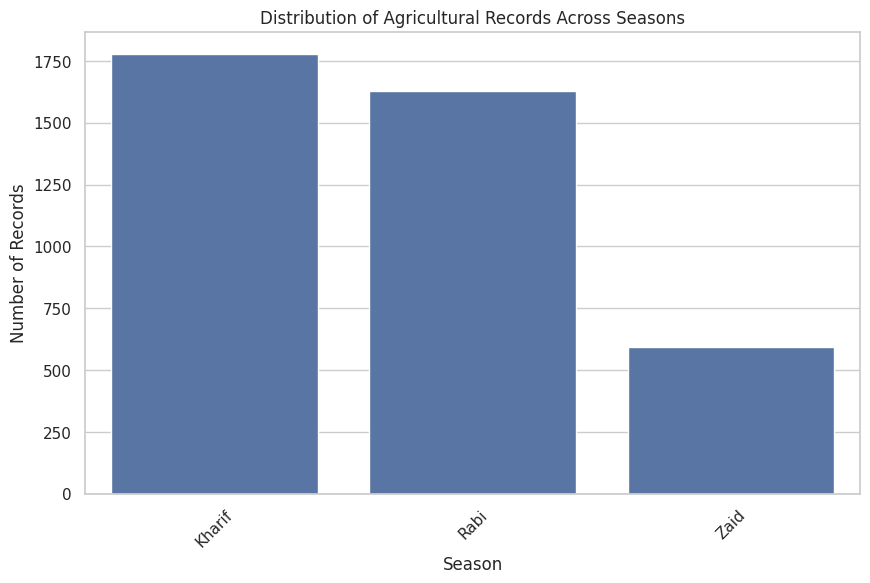

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x=season_col,
    order=df[season_col].value_counts().index
)

plt.title("Distribution of Agricultural Records Across Seasons")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

In [ ]:
season_summary = df.groupby(season_col)[numerical_columns].mean()

display(season_summary)

,farm_area_hectares,rainfall_mm,avg_temperature_c,humidity_pct,sunlight_hours_day,soil_ph,soil_moisture_pct,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,...,seed_quality_score,yield_tonnes_ha,production_tonnes,market_price_inr_tonne,total_cost_inr,revenue_inr,profit_inr,water_used_m3,water_efficiency_t_per_1000m3,disease_pest_risk_pct
season,,,,,,,,,,,,,,,,,,,,,
Kharif,7.944924,852.084205,28.454019,71.812591,6.793367,6.727993,31.198410,120.020124,58.096515,105.303485,...,0.821613,5.643973,46.311192,44850.906127,531804.408094,710719.055649,178914.647555,6102.201237,5.891834,54.467903
Rabi,7.752207,436.000124,23.489183,57.893178,7.589797,6.673749,24.050620,120.402827,57.311002,103.926060,...,0.832170,5.080498,41.486712,44747.974800,513836.578365,601526.048556,87689.470191,5846.987093,5.186122,40.482114
Zaid,8.091246,299.421784,31.042088,52.012121,8.178788,6.694865,19.170085,120.525421,58.129125,105.416835,...,0.823165,4.665942,38.886111,44212.033670,543976.728956,519171.904040,-24804.824916,6419.893939,4.413239,38.216667


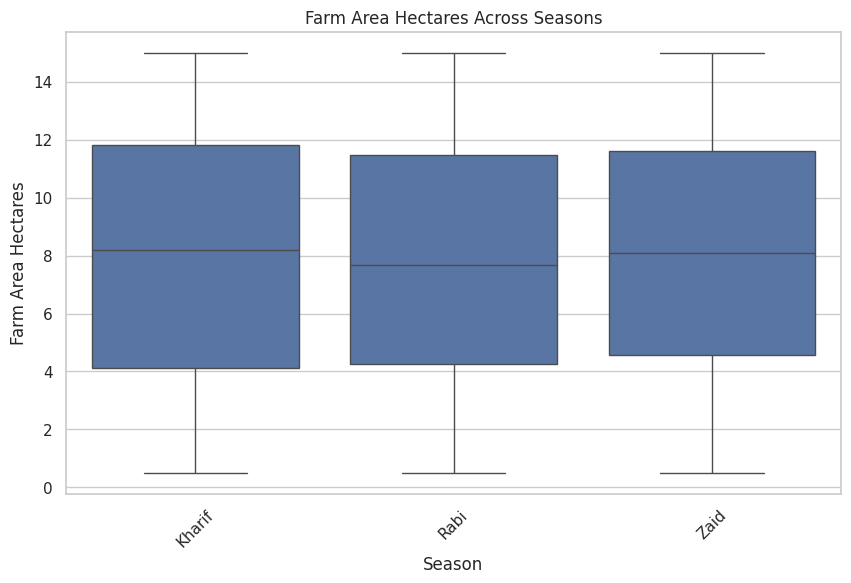

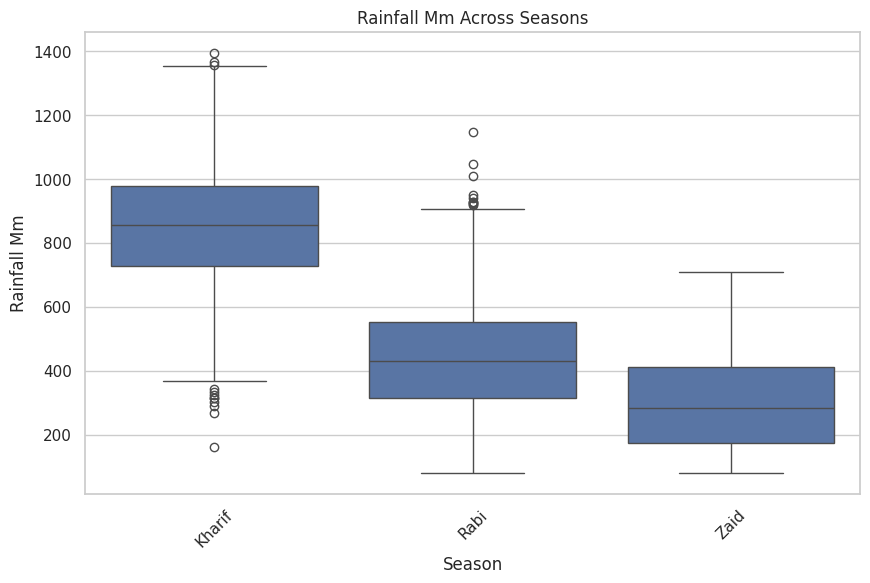

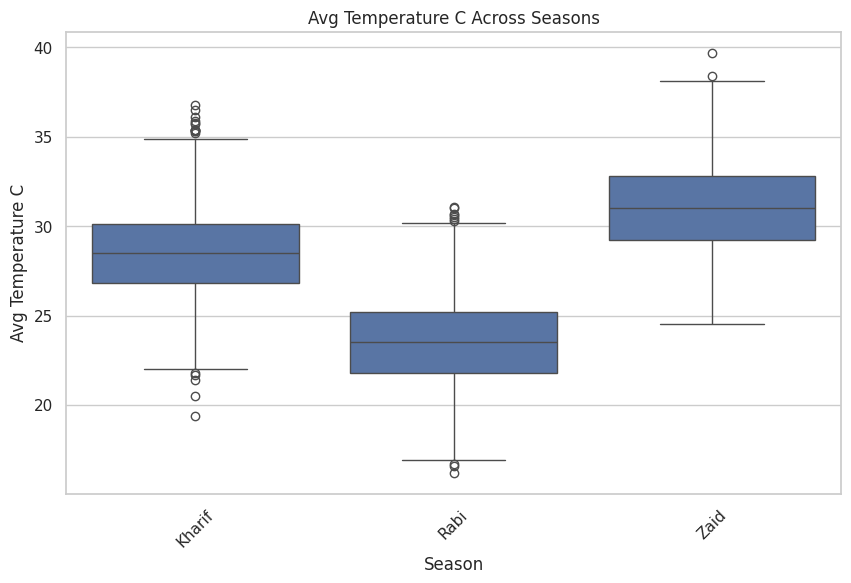

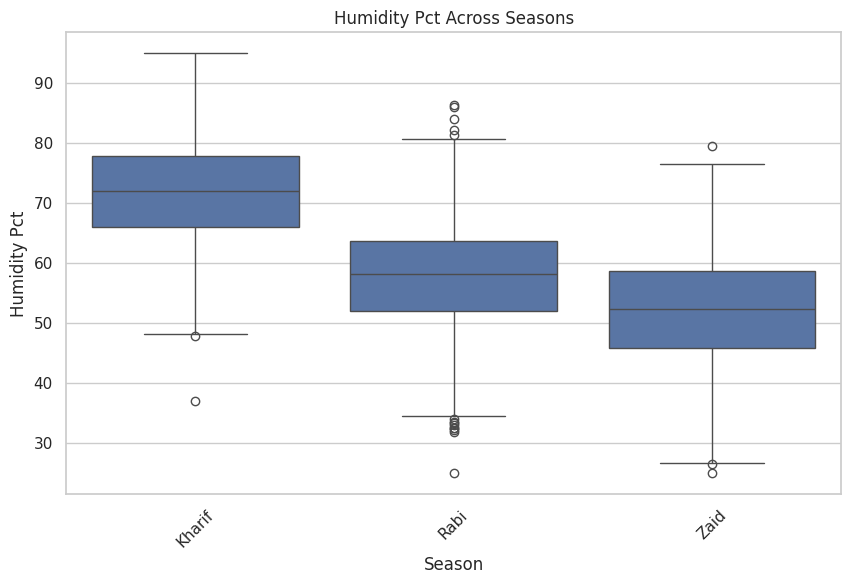

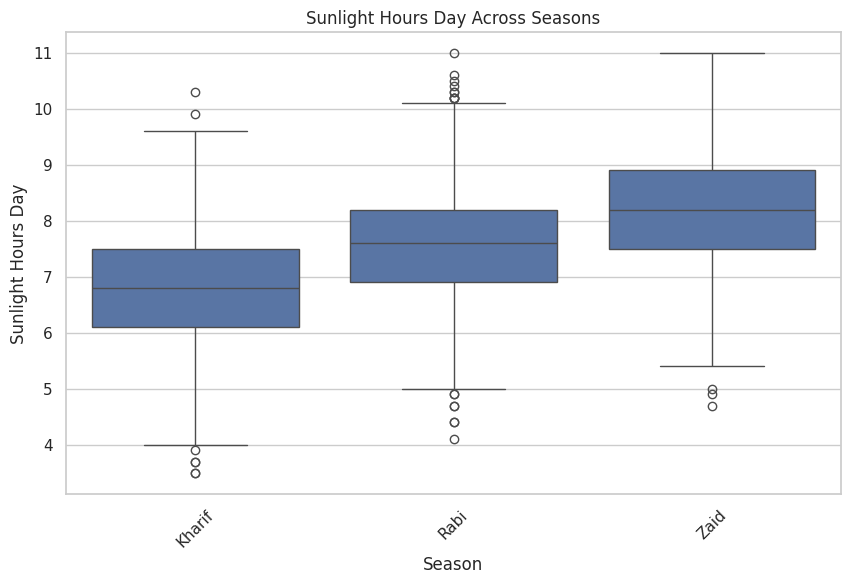

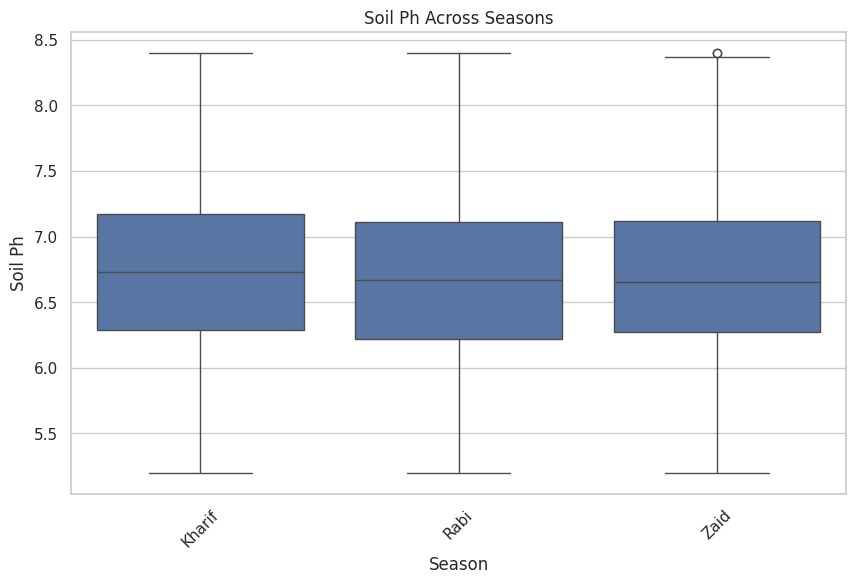

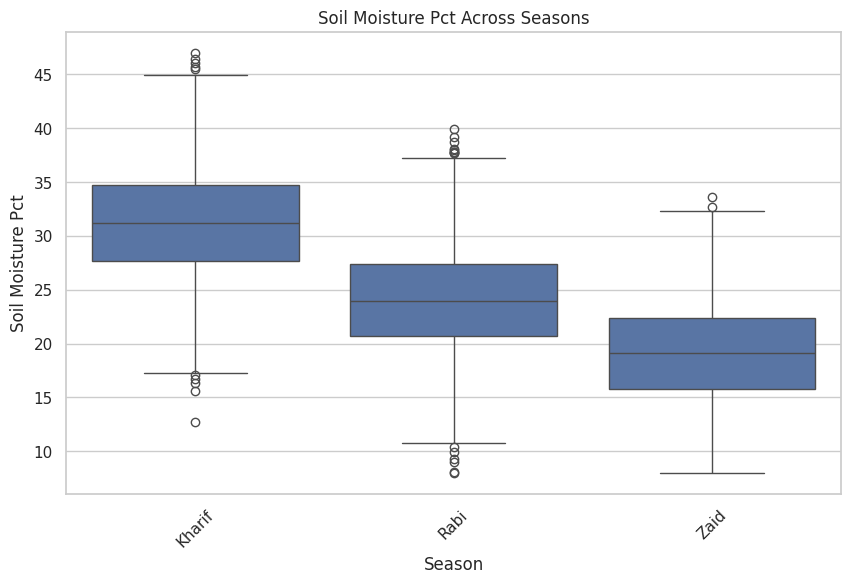

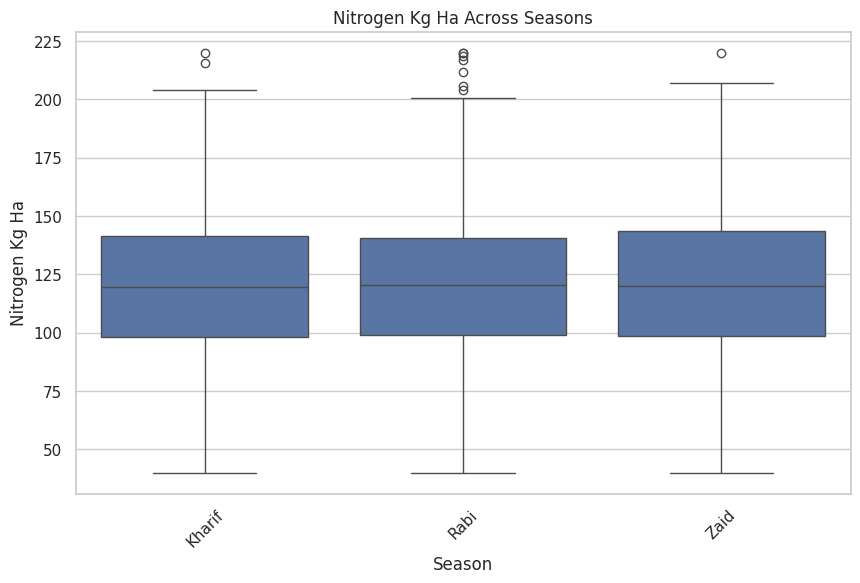

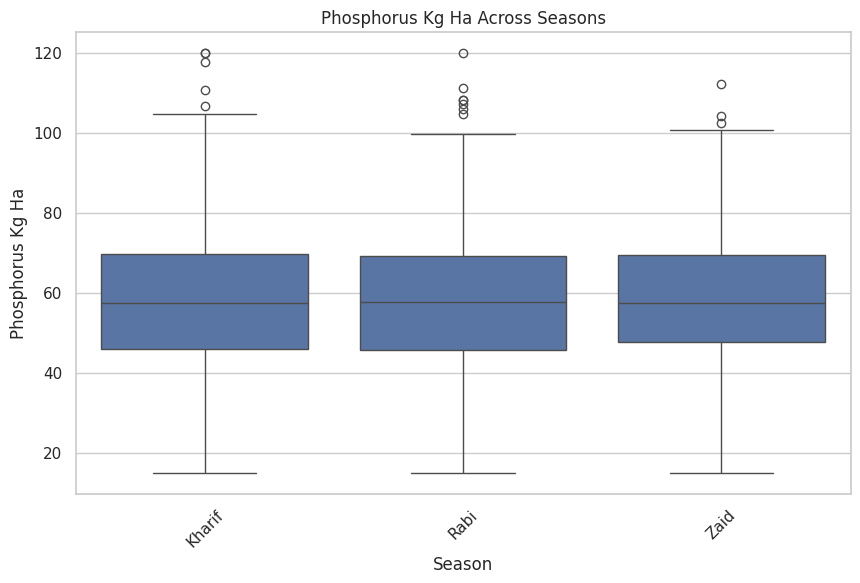

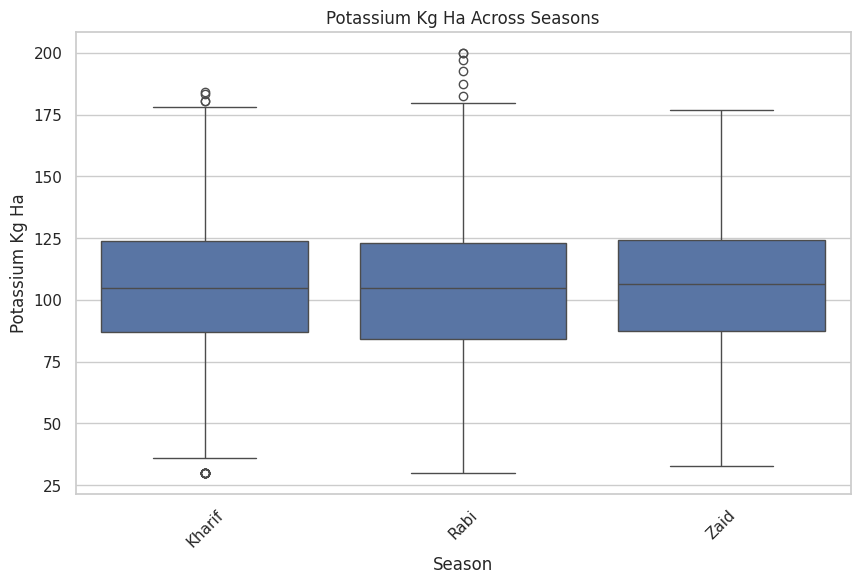

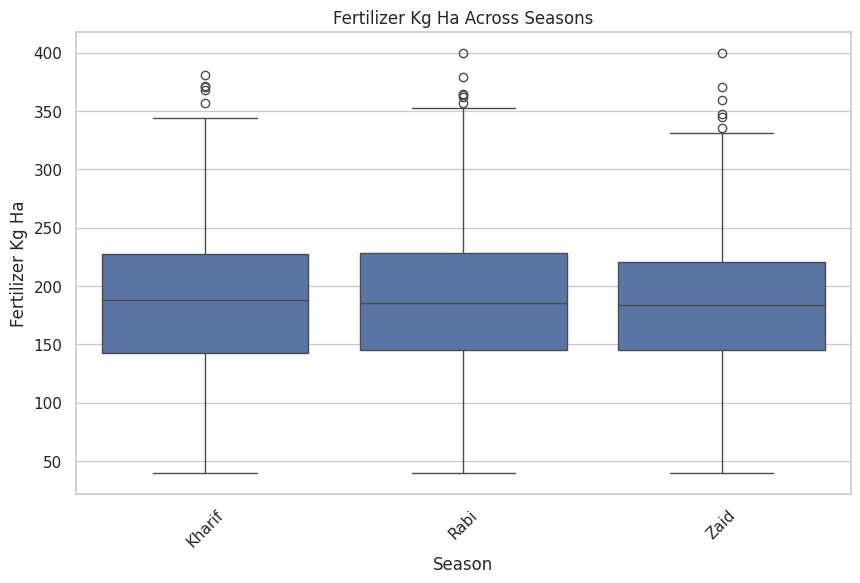

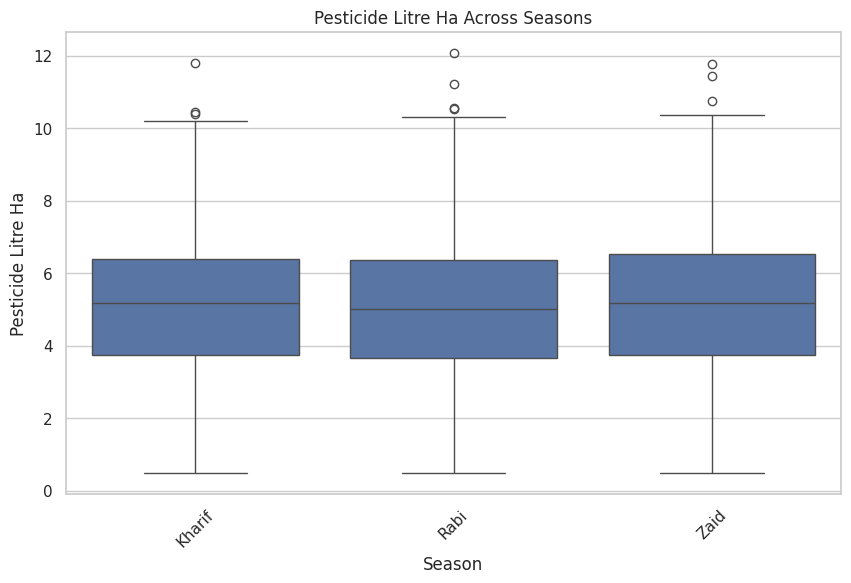

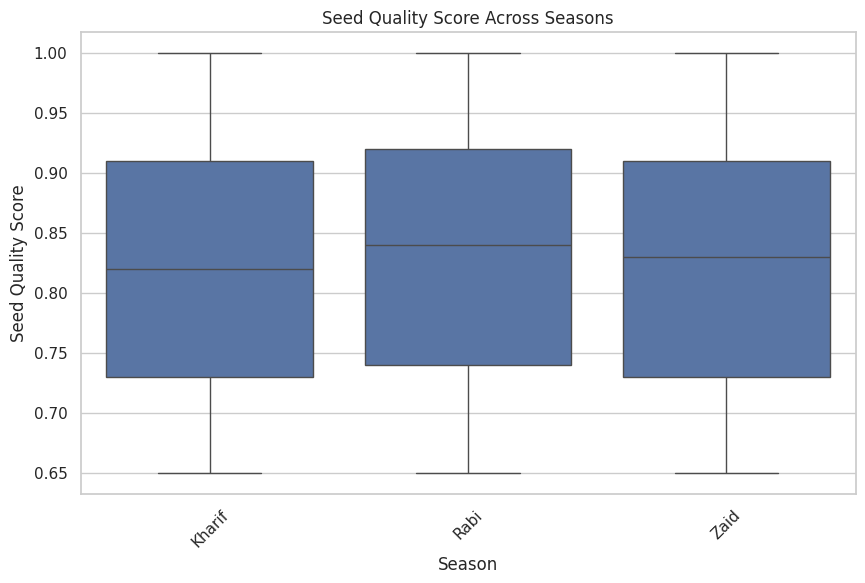

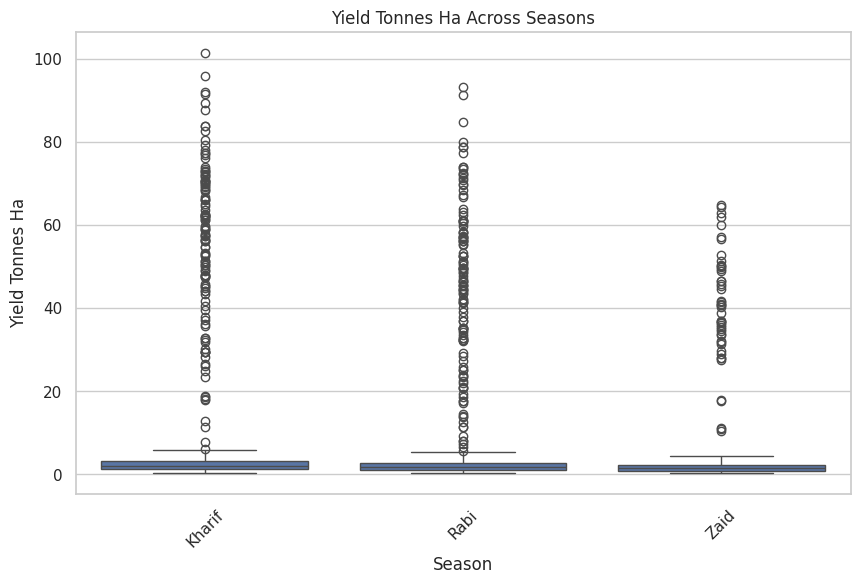

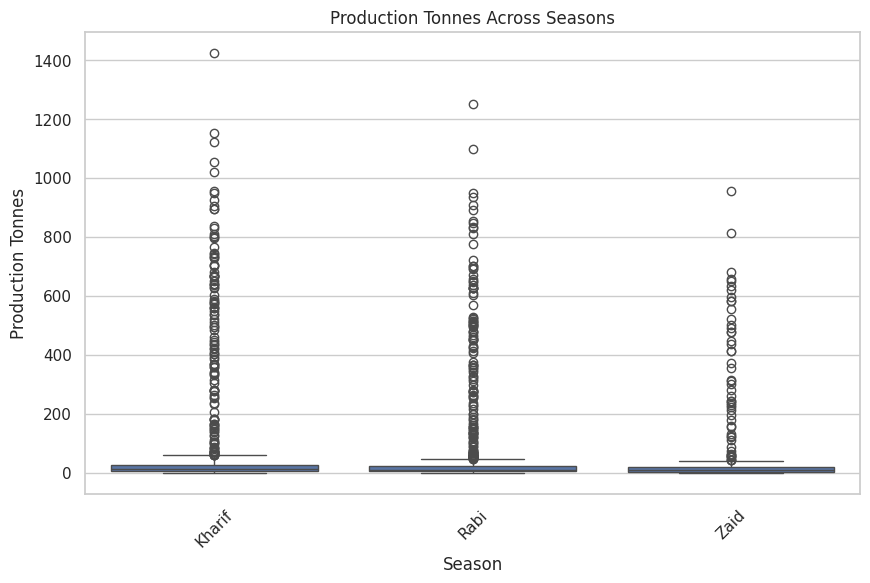

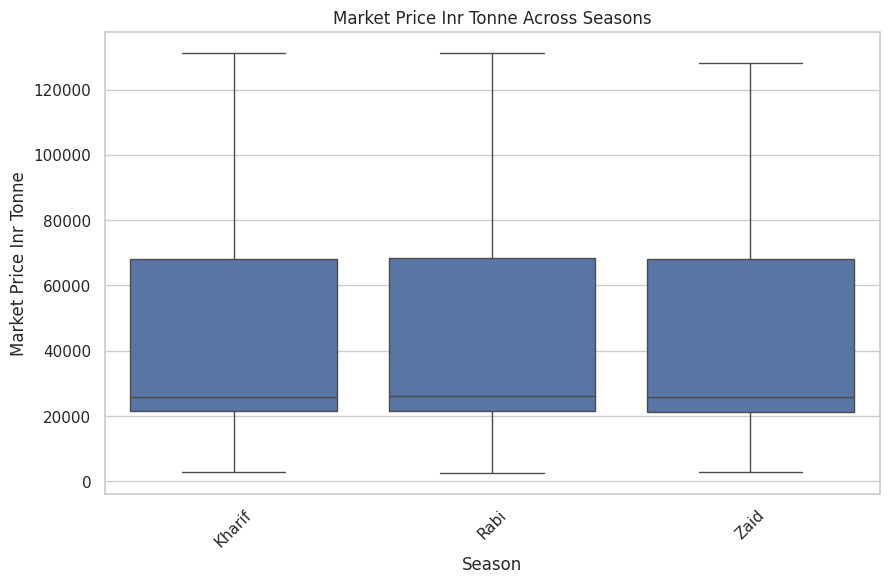

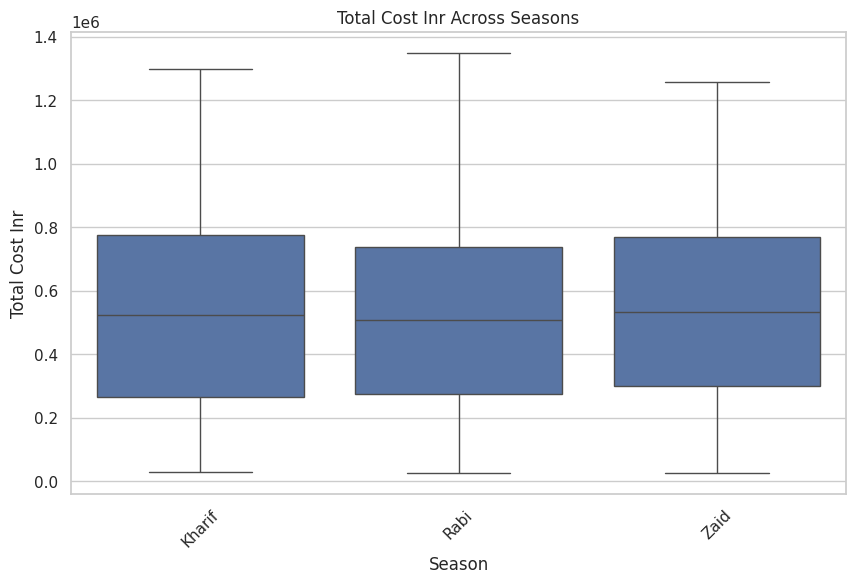

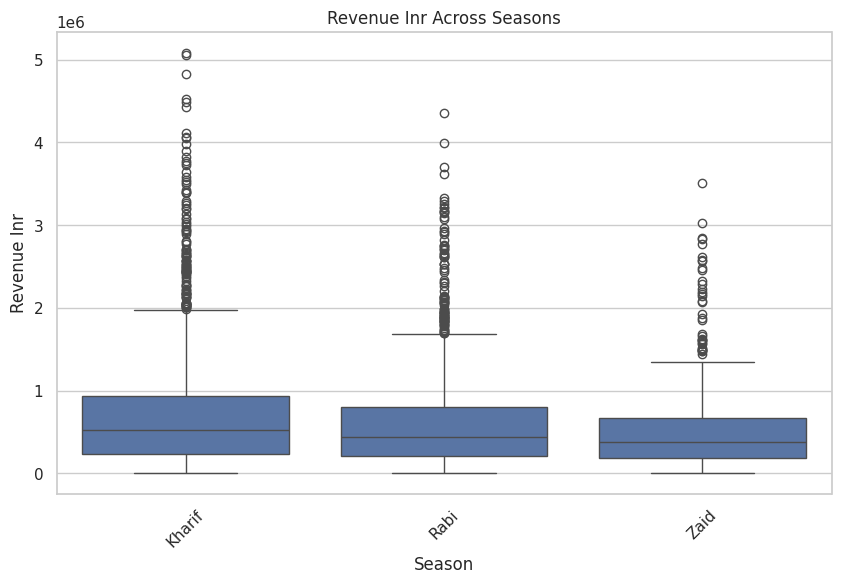

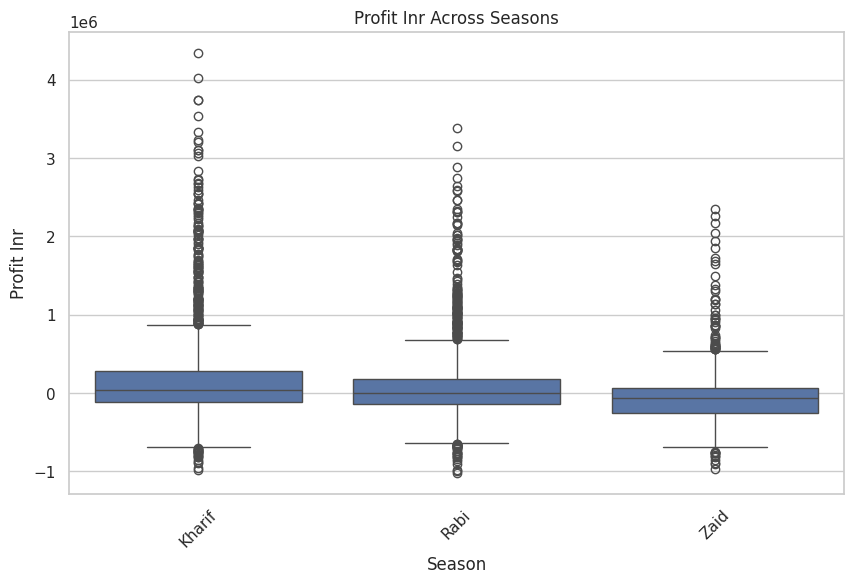

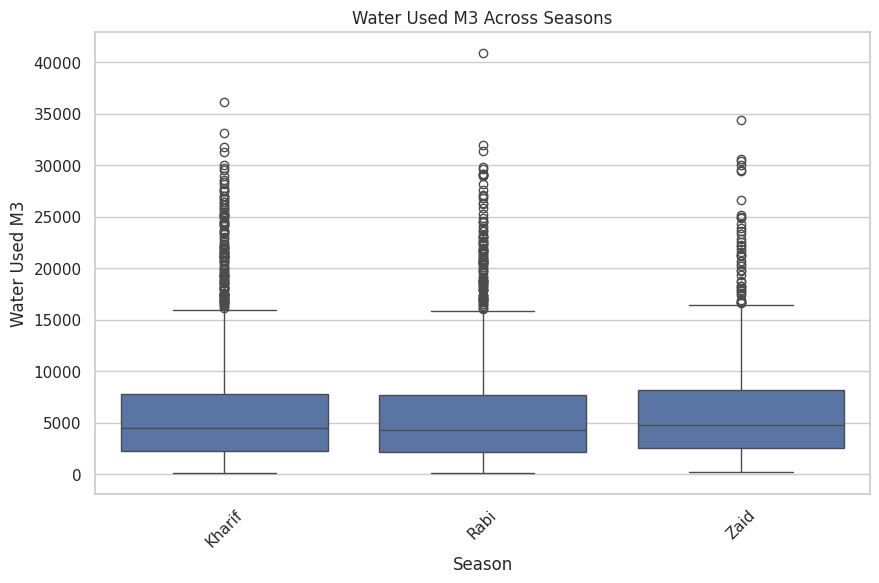

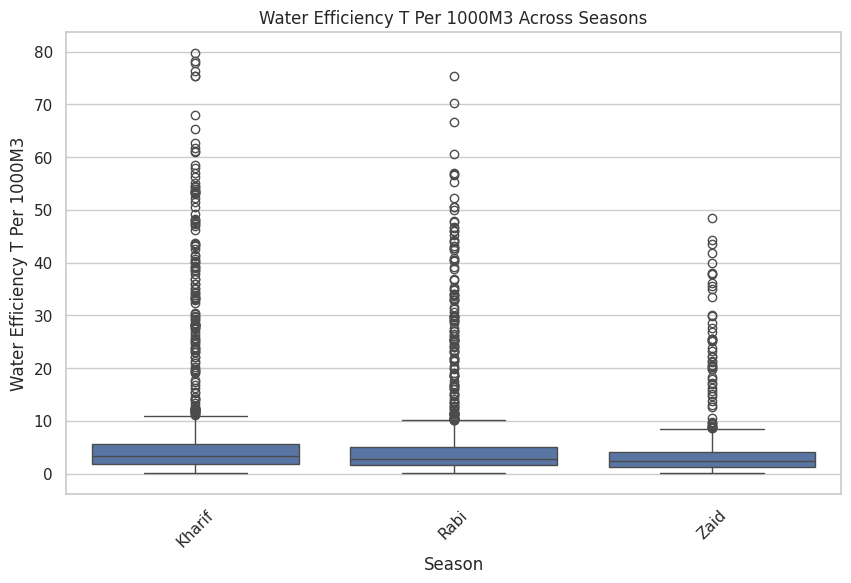

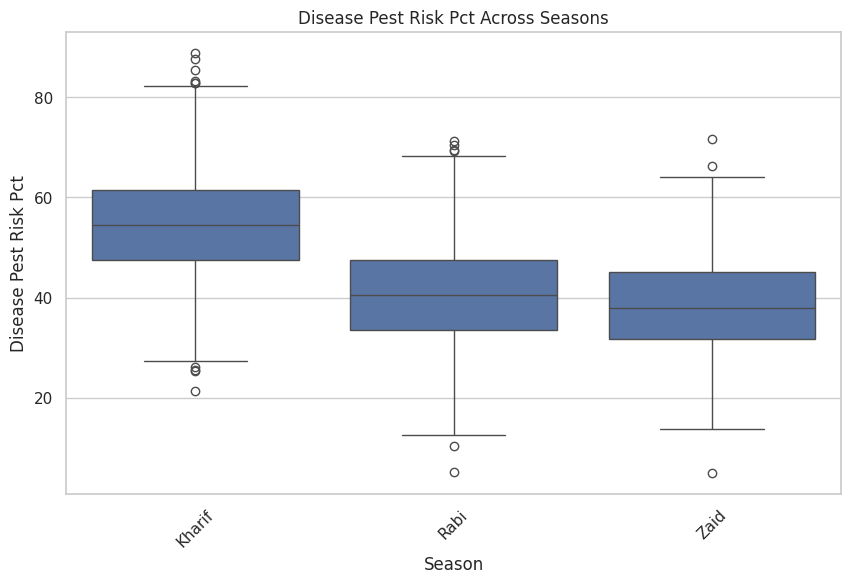

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(10,6))

    sns.boxplot(
        data=df,
        x=season_col,
        y=col
    )

    plt.title(f"{col.replace('_', ' ').title()} Across Seasons")
    plt.xlabel("Season")
    plt.ylabel(col.replace("_", " ").title())
    plt.xticks(rotation=45)

    plt.show()

In [ ]:
possible_performance = [
    col for col in numerical_columns
    if any(word in col.lower()
           for word in ["yield", "production", "output", "profit", "revenue"])
]

print("Possible Performance Columns:")
print(possible_performance)

Possible Performance Columns:
['yield_tonnes_ha', 'production_tonnes', 'revenue_inr', 'profit_inr']


In [ ]:
performance_col = "yield"

In [ ]:
# Check your actual columns and automatically select performance column

print("Available columns:")
print(df.columns.tolist())

# Automatically find a suitable performance column
possible_columns = [
    "production",
    "crop_production",
    "productivity",
    "performance",
    "output",
    "harvest",
    "yield"
]

performance_col = next(
    (col for col in possible_columns if col in df.columns),
    None
)

# If none found, use the first numeric column
if performance_col is None:
    numeric_cols = df.select_dtypes(include="number").columns.tolist()
    performance_col = numeric_cols[0]

print("Using performance column:", performance_col)

# Your original analysis
season_performance = (
    df.groupby(season_col)[performance_col]
    .agg(["mean", "median", "min", "max", "std"])
    .sort_values("mean", ascending=False)
)

display(season_performance)

Available columns:
['farm_id', 'state', 'district', 'crop', 'season', 'farm_area_hectares', 'rainfall_mm', 'avg_temperature_c', 'humidity_pct', 'sunlight_hours_day', 'soil_ph', 'soil_moisture_pct', 'nitrogen_kg_ha', 'phosphorus_kg_ha', 'potassium_kg_ha', 'irrigation_method', 'fertilizer_kg_ha', 'pesticide_litre_ha', 'seed_quality_score', 'yield_tonnes_ha', 'production_tonnes', 'market_price_inr_tonne', 'total_cost_inr', 'revenue_inr', 'profit_inr', 'water_used_m3', 'water_efficiency_t_per_1000m3', 'disease_pest_risk_pct']
Using performance column: farm_area_hectares


,mean,median,min,max,std
season,,,,,
Zaid,8.091246,8.085,0.5,14.99,4.162594
Kharif,7.944924,8.180,0.5,15.00,4.282328
Rabi,7.752207,7.680,0.5,15.00,4.179402


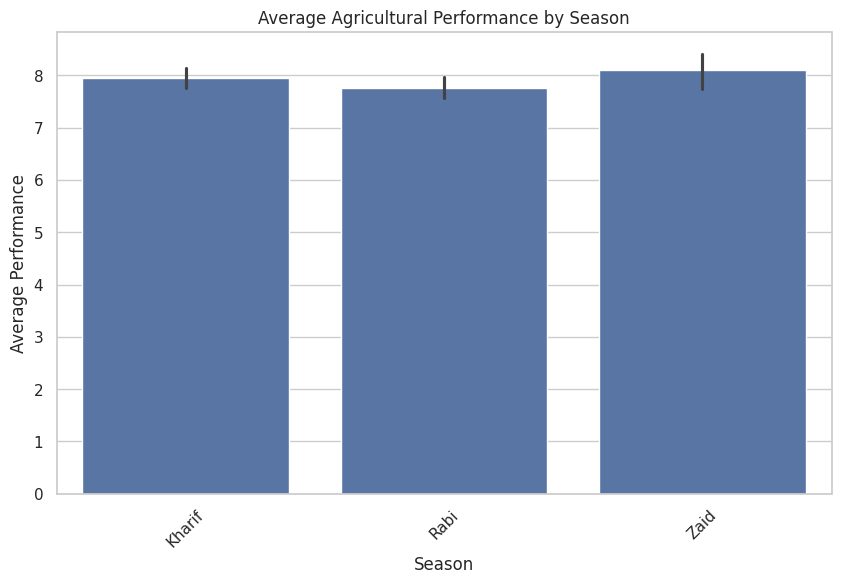

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x=season_col,
    y=performance_col,
    estimator="mean"
)

plt.title("Average Agricultural Performance by Season")
plt.xlabel("Season")
plt.ylabel("Average Performance")
plt.xticks(rotation=45)

plt.show()

In [ ]:
best_season = season_performance["mean"].idxmax()
best_value = season_performance["mean"].max()

print("Best Performing Season:", best_season)
print("Average Performance:", round(best_value, 2))

Best Performing Season: Zaid
Average Performance: 8.09


In [ ]:
worst_season = season_performance["mean"].idxmin()
worst_value = season_performance["mean"].min()

print("Lowest Performing Season:", worst_season)
print("Average Performance:", round(worst_value, 2))

Lowest Performing Season: Rabi
Average Performance: 7.75


In [ ]:
resource_columns = [
    col for col in numerical_columns
    if any(word in col.lower()
           for word in [
               "water",
               "rain",
               "fertilizer",
               "fertiliser",
               "pesticide",
               "irrigation",
               "labor",
               "labour",
               "cost",
               "resource"
           ])
]

print("Possible Resource Columns:")
print(resource_columns)

Possible Resource Columns:
['rainfall_mm', 'fertilizer_kg_ha', 'pesticide_litre_ha', 'total_cost_inr', 'water_used_m3', 'water_efficiency_t_per_1000m3']


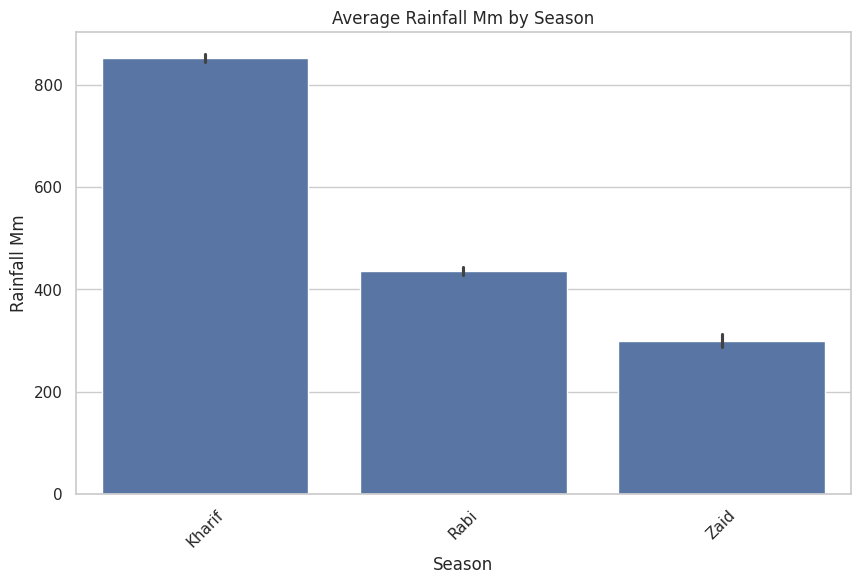

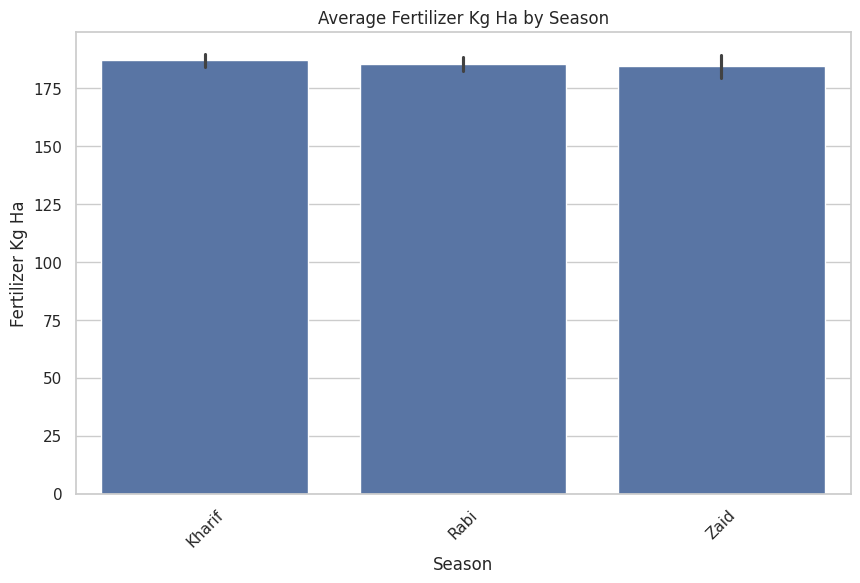

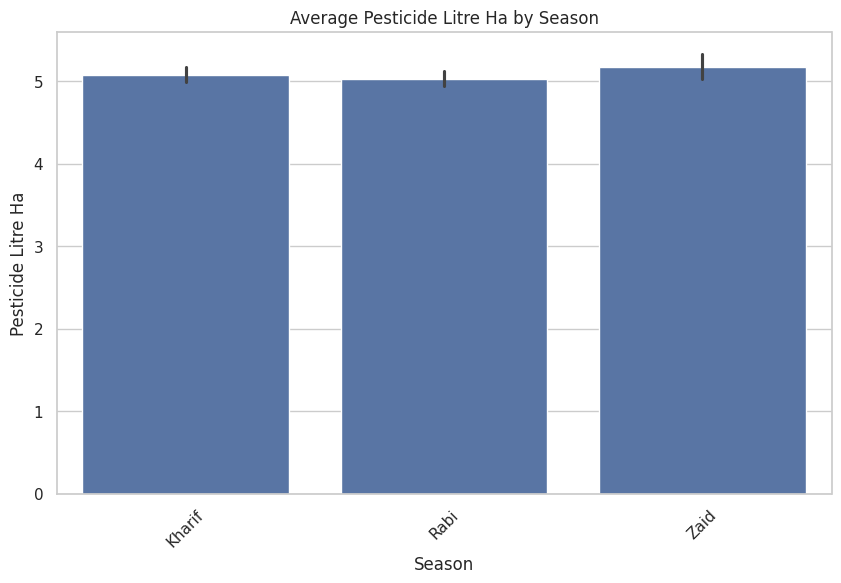

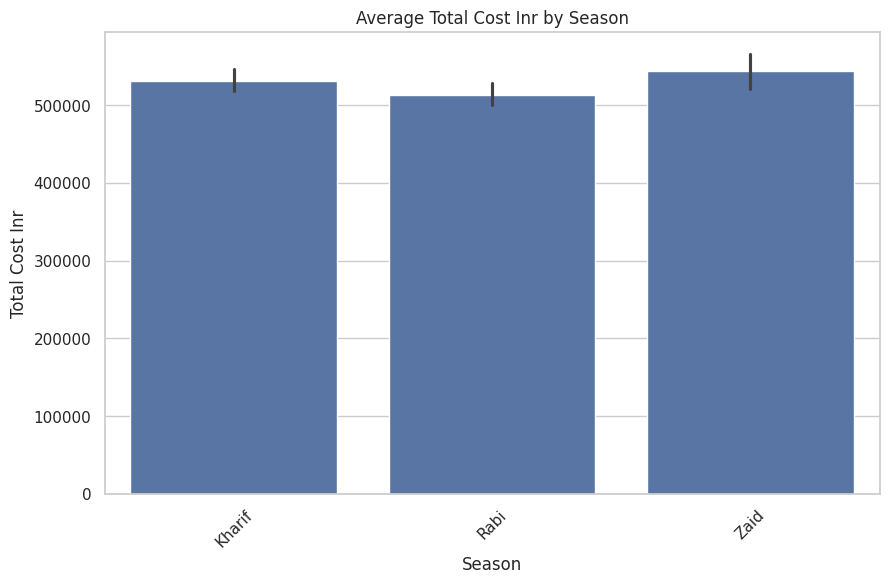

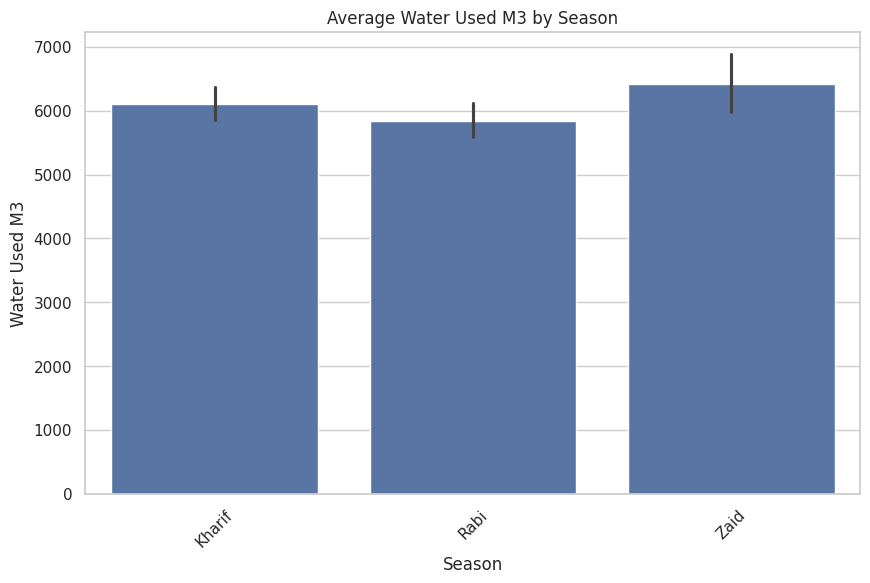

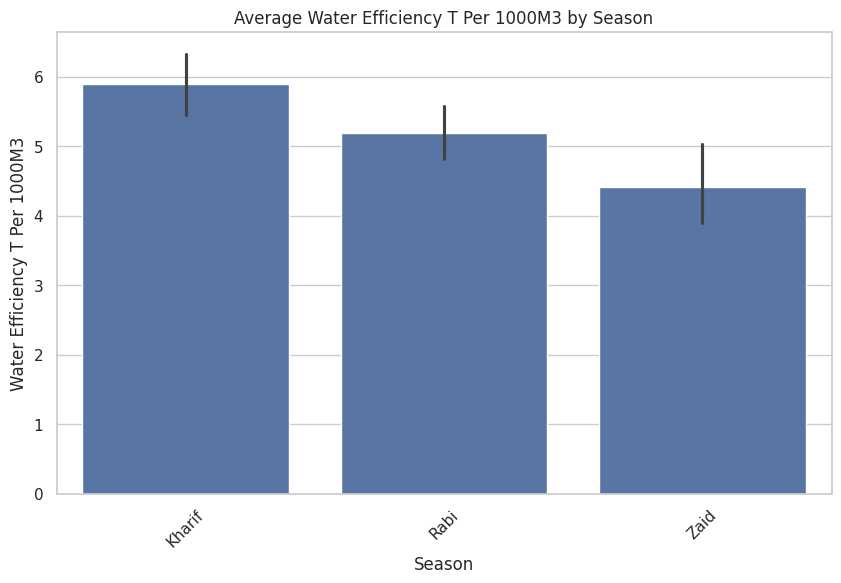

In [ ]:
for col in resource_columns:

    plt.figure(figsize=(10,6))

    sns.barplot(
        data=df,
        x=season_col,
        y=col,
        estimator="mean"
    )

    plt.title(f"Average {col.replace('_', ' ').title()} by Season")
    plt.xlabel("Season")
    plt.ylabel(col.replace("_", " ").title())
    plt.xticks(rotation=45)

    plt.show()

In [ ]:
environment_columns = [
    col for col in numerical_columns
    if any(word in col.lower()
           for word in [
               "temperature",
               "humidity",
               "rainfall",
               "rain",
               "soil",
               "moisture",
               "sunlight",
               "weather",
               "pressure"
           ])
]

print("Environmental Columns:")
print(environment_columns)

Environmental Columns:
['rainfall_mm', 'avg_temperature_c', 'humidity_pct', 'sunlight_hours_day', 'soil_ph', 'soil_moisture_pct']


In [ ]:
if environment_columns:

    environment_summary = df.groupby(
        season_col
    )[environment_columns].mean()

    display(environment_summary)

,rainfall_mm,avg_temperature_c,humidity_pct,sunlight_hours_day,soil_ph,soil_moisture_pct
season,,,,,,
Kharif,852.084205,28.454019,71.812591,6.793367,6.727993,31.198410
Rabi,436.000124,23.489183,57.893178,7.589797,6.673749,24.050620
Zaid,299.421784,31.042088,52.012121,8.178788,6.694865,19.170085


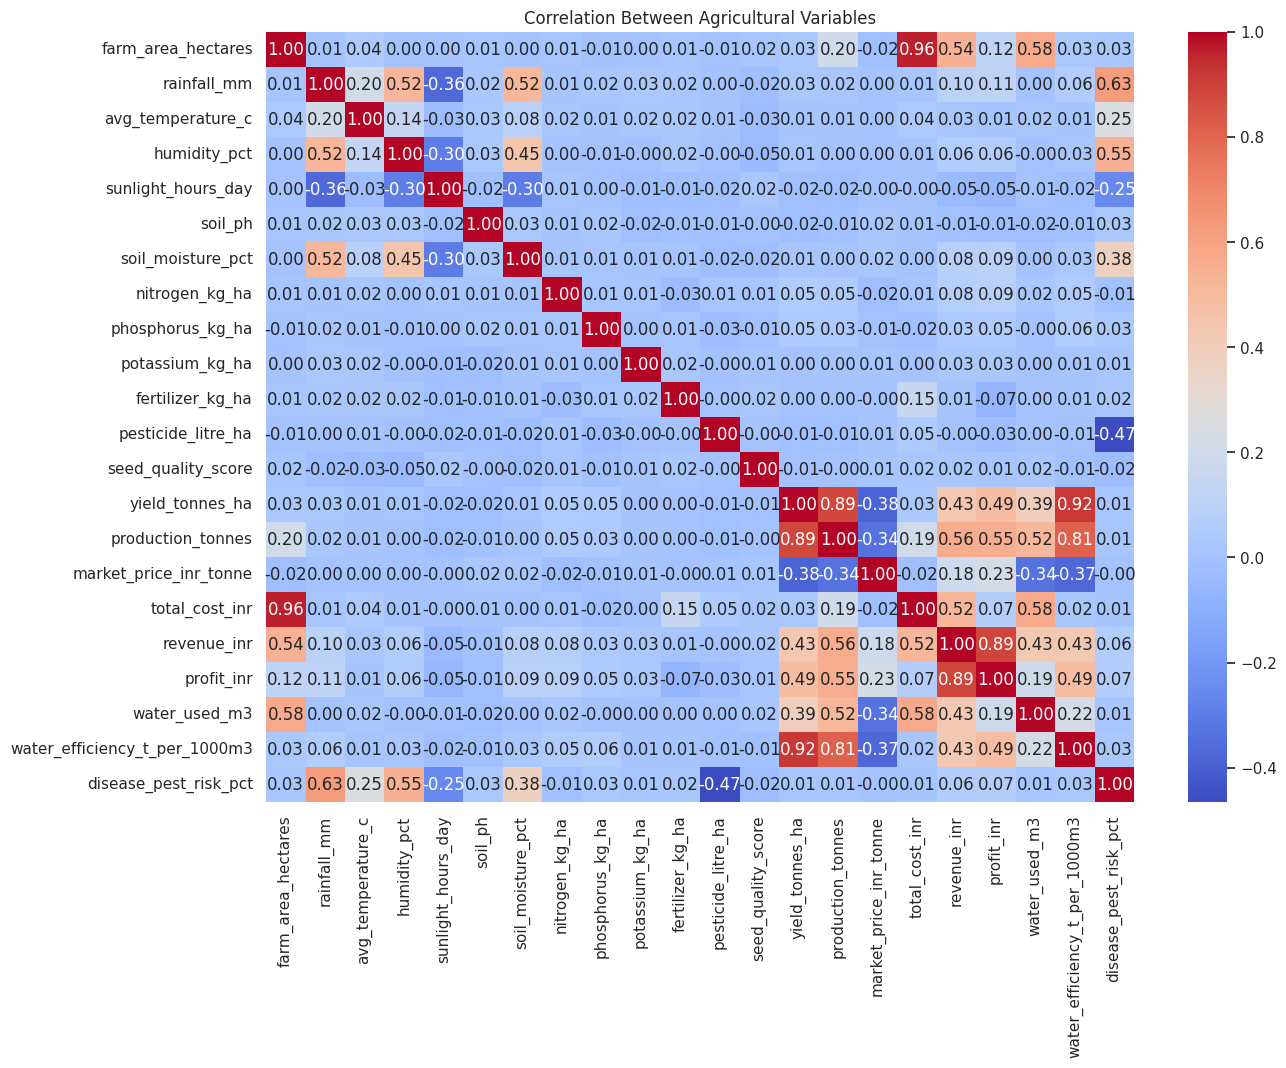

In [ ]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Agricultural Variables")

plt.show()

In [ ]:
performance_correlation = (
    correlation[performance_col]
    .sort_values(ascending=False)
)

display(performance_correlation)

,farm_area_hectares
farm_area_hectares,1.000000
total_cost_inr,0.962211
water_used_m3,0.576015
revenue_inr,0.543364
production_tonnes,0.197842
profit_inr,0.115241
avg_temperature_c,0.036870
yield_tonnes_ha,0.030188
water_efficiency_t_per_1000m3,0.028930
disease_pest_risk_pct,0.025963


In [ ]:
if "rainfall" in df.columns:

    plt.figure(figsize=(10,6))

    sns.scatterplot(
        data=df,
        x="rainfall",
        y=performance_col,
        hue=season_col
    )

    plt.title("Rainfall vs Agricultural Performance")
    plt.xlabel("Rainfall")
    plt.ylabel("Agricultural Performance")

    plt.show()

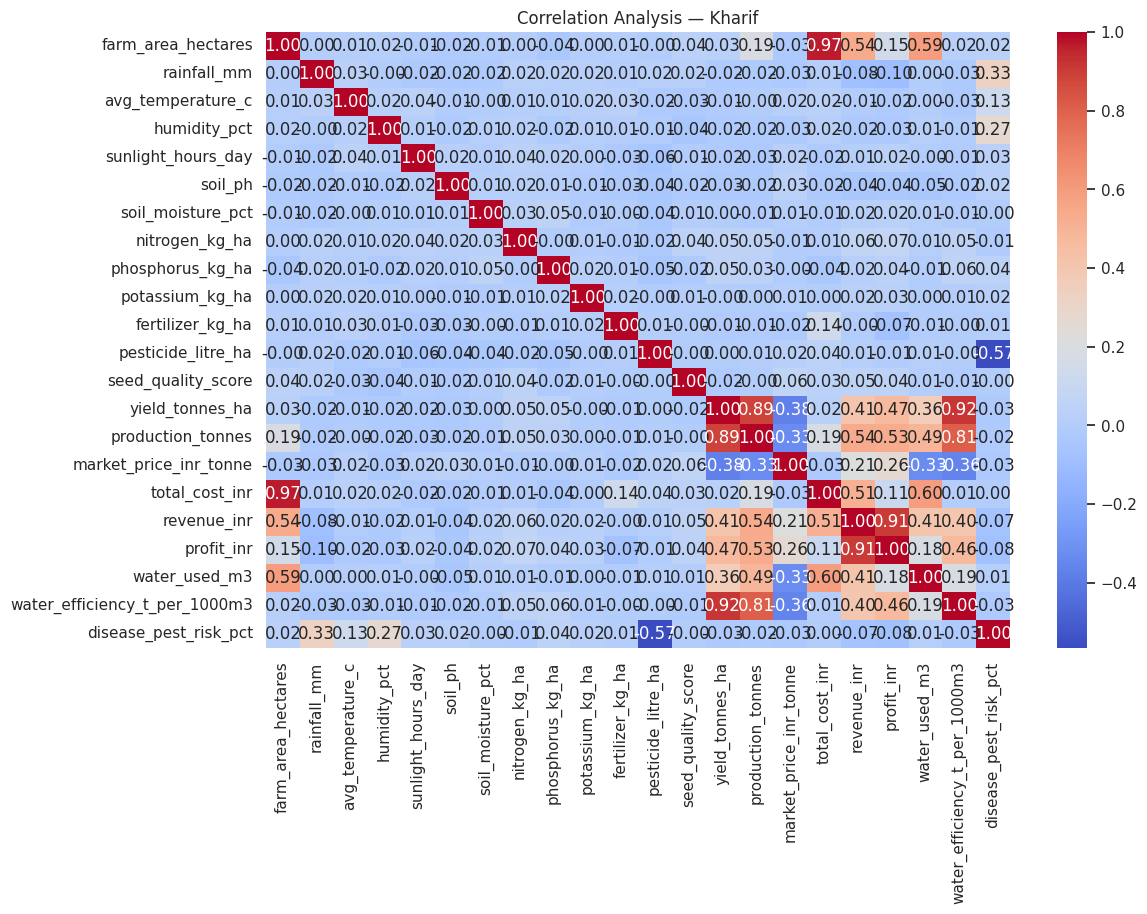

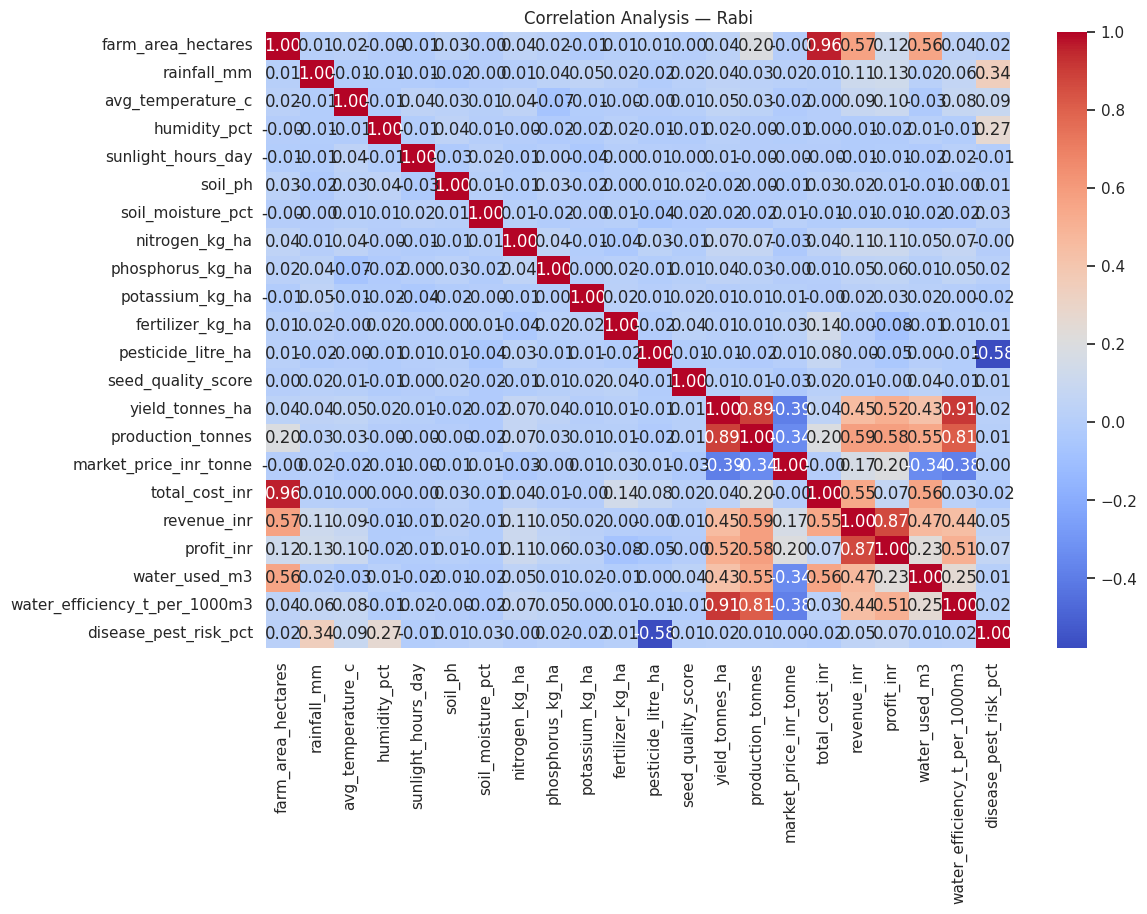

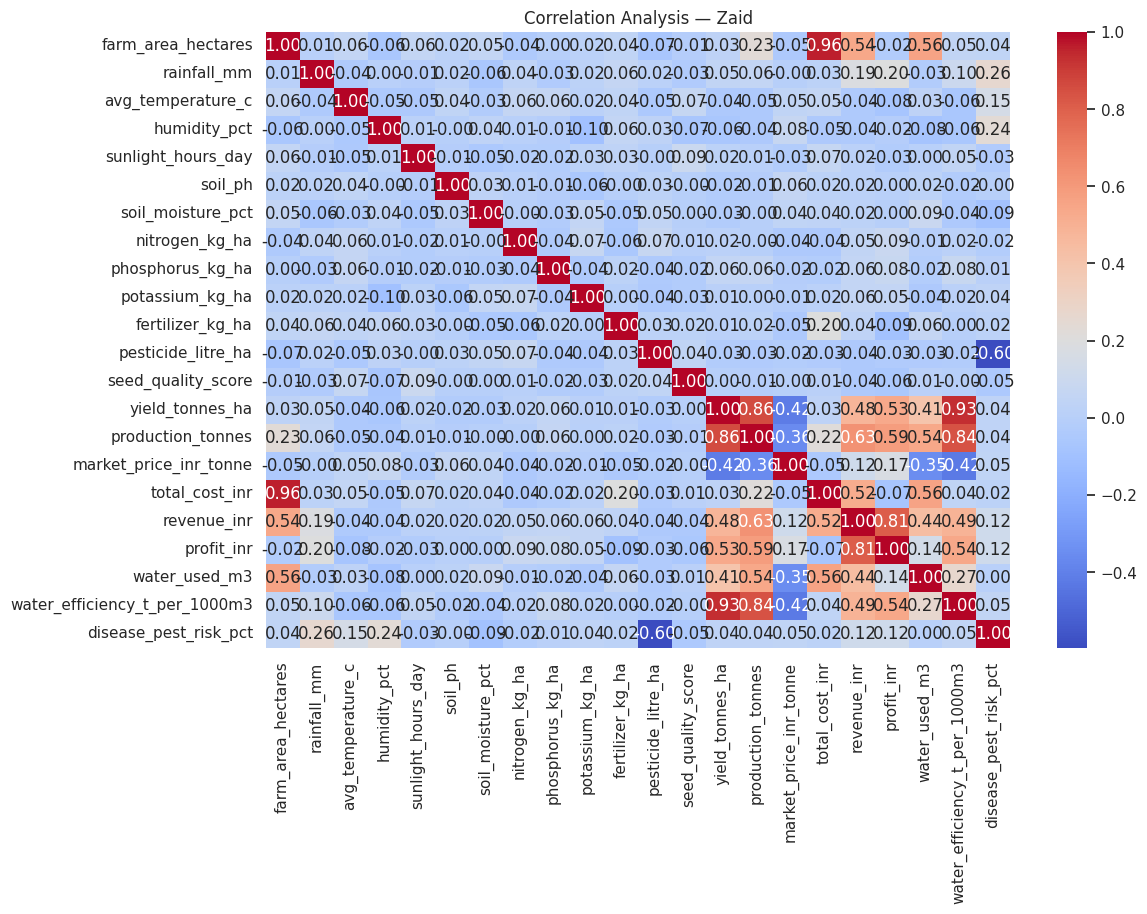

In [ ]:
for season in df[season_col].dropna().unique():

    season_data = df[df[season_col] == season]

    if len(season_data) > 2:

        corr = season_data[numerical_columns].corr()

        plt.figure(figsize=(12,8))

        sns.heatmap(
            corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f"
        )

        plt.title(f"Correlation Analysis — {season}")

        plt.show()

In [ ]:
possible_region_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["region", "area", "location", "district", "state"])
]

print(possible_region_columns)

['state', 'district', 'farm_area_hectares']


In [ ]:
region_col = "region"

In [ ]:
# Automatically find the region/location column

region_candidates = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["region", "area", "location", "district", "state"])
]

if not region_candidates:
    print("Region column not found.")
    print("Available columns:")
    print(df.columns.tolist())
else:
    region_col = region_candidates[0]

    print("Using Region Column:", region_col)
    print("Using Season Column:", season_col)
    print("Using Performance Column:", performance_col)

    regional_analysis = pd.pivot_table(
        df,
        values=performance_col,
        index=region_col,
        columns=season_col,
        aggfunc="mean"
    )

    display(regional_analysis)

Using Region Column: state
Using Season Column: season
Using Performance Column: farm_area_hectares


season,Kharif,Rabi,Zaid
state,,,
Andhra Pradesh,7.840417,7.795931,8.944588
Gujarat,8.036244,7.898250,8.118507
Karnataka,8.321340,7.707573,7.937568
Madhya Pradesh,7.640841,7.805962,7.650317
Maharashtra,7.452973,7.939817,7.834028
Punjab,8.284932,8.296290,7.901039
Tamil Nadu,8.264126,6.988510,7.867746
Telangana,7.787949,7.633604,8.253882


In [ ]:
region_col = "region"

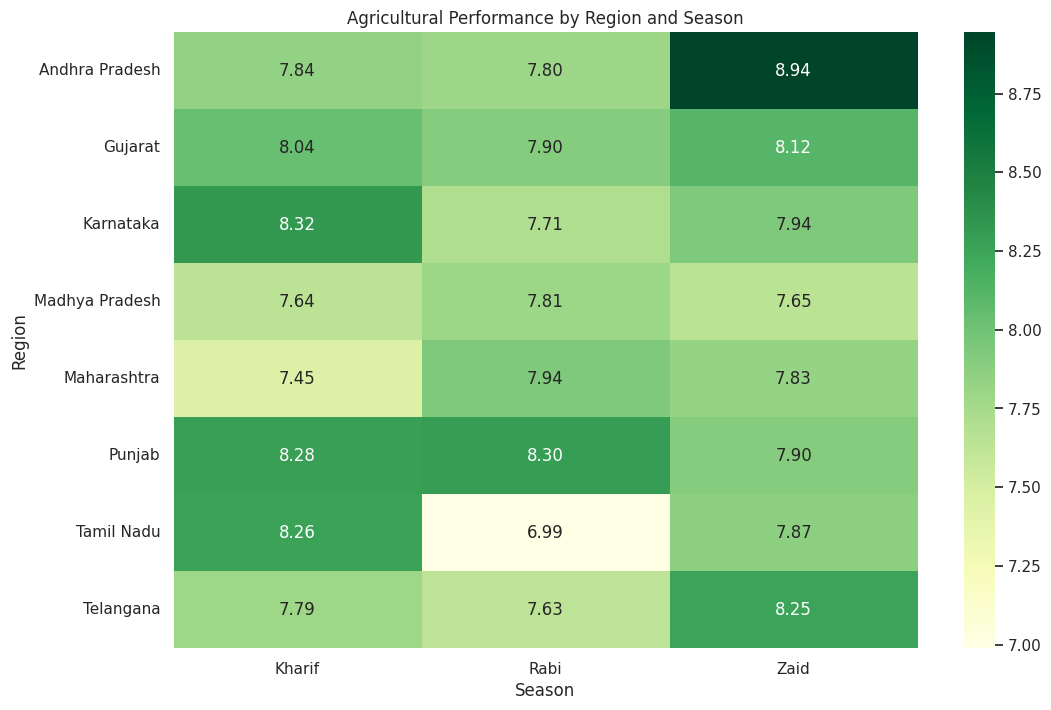

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    regional_analysis,
    annot=True,
    fmt=".2f",
    cmap="YlGn"
)

plt.title("Agricultural Performance by Region and Season")
plt.xlabel("Season")
plt.ylabel("Region")

plt.show()

In [ ]:
groups = []

for season in df[season_col].dropna().unique():

    values = df.loc[
        df[season_col] == season,
        performance_col
    ].dropna()

    groups.append(values)

if len(groups) >= 2:

    anova_result = stats.f_oneway(*groups)

    print("ANOVA F-statistic:", round(anova_result.statistic, 4))
    print("ANOVA p-value:", round(anova_result.pvalue, 6))

ANOVA F-statistic: 1.6907
ANOVA p-value: 0.184525


In [ ]:
alpha = 0.05

if anova_result.pvalue < alpha:
    print("Result: Significant difference exists between seasons.")
else:
    print("Result: No statistically significant difference detected.")

Result: No statistically significant difference detected.


In [ ]:
Q1 = df[performance_col].quantile(0.25)
Q3 = df[performance_col].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[performance_col] < lower_bound) |
    (df[performance_col] > upper_bound)
]

print("Number of outliers:", len(outliers))

display(outliers.head(10))

Number of outliers: 0


,farm_id,state,district,crop,season,farm_area_hectares,rainfall_mm,avg_temperature_c,humidity_pct,sunlight_hours_day,...,seed_quality_score,yield_tonnes_ha,production_tonnes,market_price_inr_tonne,total_cost_inr,revenue_inr,profit_inr,water_used_m3,water_efficiency_t_per_1000m3,disease_pest_risk_pct


In [ ]:
top_records = df.sort_values(
    by=performance_col,
    ascending=False
).head(10)

display(top_records)

,farm_id,state,district,crop,season,farm_area_hectares,rainfall_mm,avg_temperature_c,humidity_pct,sunlight_hours_day,...,seed_quality_score,yield_tonnes_ha,production_tonnes,market_price_inr_tonne,total_cost_inr,revenue_inr,profit_inr,water_used_m3,water_efficiency_t_per_1000m3,disease_pest_risk_pct
3356,SF13357,Gujarat,Rajkot,Pulses,Kharif,15.00,1045.2,29.5,83.5,6.8,...,0.67,0.97,14.55,70265,1139207,1022356,-116851,6512,2.234,67.3
1989,SF11990,Gujarat,Rajkot,Wheat,Rabi,15.00,380.8,21.8,58.7,7.9,...,0.92,2.78,41.70,24672,1349990,1028822,-321168,7887,5.287,37.6
3897,SF13898,Karnataka,Rajkot,Sugarcane,Zaid,14.99,292.5,26.4,55.6,8.8,...,0.79,31.82,476.98,3365,898221,1605038,706817,29415,16.216,38.2
3750,SF13751,Maharashtra,Krishna,Sugarcane,Kharif,14.99,633.2,29.0,82.1,6.2,...,0.72,70.28,1053.50,3393,1013796,3574526,2560730,26177,40.245,48.6
2775,SF12776,Telangana,Nashik,Pulses,Rabi,14.99,348.0,27.3,56.3,8.2,...,0.99,1.08,16.19,61399,701841,994050,292209,3403,4.758,37.1
166,SF10167,Maharashtra,Warangal,Chilli,Kharif,14.99,697.7,27.4,61.3,6.5,...,0.99,0.70,10.49,102884,940792,1079253,138461,8999,1.166,48.6
3363,SF13364,Gujarat,Rajkot,Cotton,Kharif,14.98,973.5,34.6,66.6,6.7,...,0.93,0.60,8.99,53367,930014,479769,-450245,14285,0.629,43.6
947,SF10948,Telangana,Nalgonda,Pulses,Kharif,14.97,910.5,30.5,84.2,7.7,...,0.96,0.30,4.49,57324,1070866,257385,-813481,6753,0.665,69.6
3027,SF13028,Punjab,Warangal,Sugarcane,Rabi,14.97,299.2,24.0,46.5,7.8,...,0.76,73.44,1099.40,3288,967925,3614827,2646902,21717,50.624,36.7
2052,SF12053,Madhya Pradesh,Ludhiana,Pulses,Rabi,14.97,443.9,21.9,55.4,8.6,...,0.94,0.34,5.09,76015,842003,386916,-455087,5482,0.928,43.9


In [ ]:
lowest_records = df.sort_values(
    by=performance_col,
    ascending=True
).head(10)

display(lowest_records)

,farm_id,state,district,crop,season,farm_area_hectares,rainfall_mm,avg_temperature_c,humidity_pct,sunlight_hours_day,...,seed_quality_score,yield_tonnes_ha,production_tonnes,market_price_inr_tonne,total_cost_inr,revenue_inr,profit_inr,water_used_m3,water_efficiency_t_per_1000m3,disease_pest_risk_pct
994,SF10995,Tamil Nadu,Rajkot,Wheat,Rabi,0.50,300.1,22.8,53.9,7.5,...,0.85,2.17,1.08,19410,34712,20963,-13749,223,4.843,27.1
3255,SF13256,Tamil Nadu,Ludhiana,Groundnut,Rabi,0.50,307.7,25.9,54.5,6.3,...,0.94,NaN,0.83,66904,30044,55530,25486,315,2.635,27.3
1200,SF11201,Tamil Nadu,Indore,Wheat,Zaid,0.50,356.7,29.8,41.1,7.9,...,0.66,0.77,0.38,18322,26826,6962,-19864,189,2.011,42.4
2492,SF12493,Madhya Pradesh,Guntur,Maize,Kharif,0.50,756.5,30.2,70.5,7.0,...,0.73,2.33,1.16,20071,32932,23282,-9650,173,6.705,37.7
496,SF10497,Tamil Nadu,Rajkot,Pulses,Zaid,0.51,NaN,31.2,68.7,8.0,...,0.75,0.30,0.15,79617,41910,11943,-29967,232,0.647,40.3
1121,SF11122,Maharashtra,Erode,Cotton,Rabi,0.51,336.5,22.8,59.9,6.1,...,0.87,1.09,0.56,70858,31404,39680,8276,191,2.932,41.9
2937,SF12938,Karnataka,Raichur,Groundnut,Kharif,0.52,938.4,28.1,71.4,5.4,...,0.75,1.74,0.90,58315,34504,52484,17980,373,2.413,59.4
3212,SF13213,Tamil Nadu,Raichur,Wheat,Rabi,0.52,515.3,24.3,57.6,7.1,...,0.96,3.67,1.91,26943,40511,51461,10950,275,6.945,37.5
1667,SF11668,Maharashtra,Nashik,Rice,Rabi,0.53,80.0,21.6,51.7,7.3,...,0.88,1.96,1.04,21192,37621,22040,-15581,651,1.598,19.6
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3


In [ ]:
print("=" * 60)
print("SEASONAL AGRICULTURE PERFORMANCE ANALYSIS")
print("=" * 60)

print("\nDataset Size:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nSeasons:")
print(df[season_col].unique())

print("\nBest Performing Season:")
print(best_season)

print("\nBest Average Performance:")
print(round(best_value, 2))

print("\nLowest Performing Season:")
print(worst_season)

print("\nLowest Average Performance:")
print(round(worst_value, 2))

SEASONAL AGRICULTURE PERFORMANCE ANALYSIS

Dataset Size:
Rows: 4000
Columns: 28

Seasons:
['Kharif' 'Rabi' 'Zaid']

Best Performing Season:
Zaid

Best Average Performance:
8.09

Lowest Performing Season:
Rabi

Lowest Average Performance:
7.75


In [ ]:
season_means = df.groupby(season_col)[performance_col].mean()

best = season_means.idxmax()
worst = season_means.idxmin()

difference = season_means.max() - season_means.min()

print("KEY INSIGHTS")
print("-" * 50)

print(
    f"1. {best} recorded the highest average "
    f"{performance_col.replace('_', ' ')} "
    f"of {season_means.max():.2f}."
)

print(
    f"2. {worst} recorded the lowest average "
    f"{performance_col.replace('_', ' ')} "
    f"of {season_means.min():.2f}."
)

print(
    f"3. The difference between the highest and "
    f"lowest seasonal averages is {difference:.2f}."
)

print(
    f"4. The analysis contains "
    f"{df[season_col].nunique()} different seasons."
)

print(
    f"5. The dataset contains {len(df):,} agricultural records."
)

KEY INSIGHTS
--------------------------------------------------
1. Zaid recorded the highest average farm area hectares of 8.09.
2. Rabi recorded the lowest average farm area hectares of 7.75.
3. The difference between the highest and lowest seasonal averages is 0.34.
4. The analysis contains 3 different seasons.
5. The dataset contains 4,000 agricultural records.


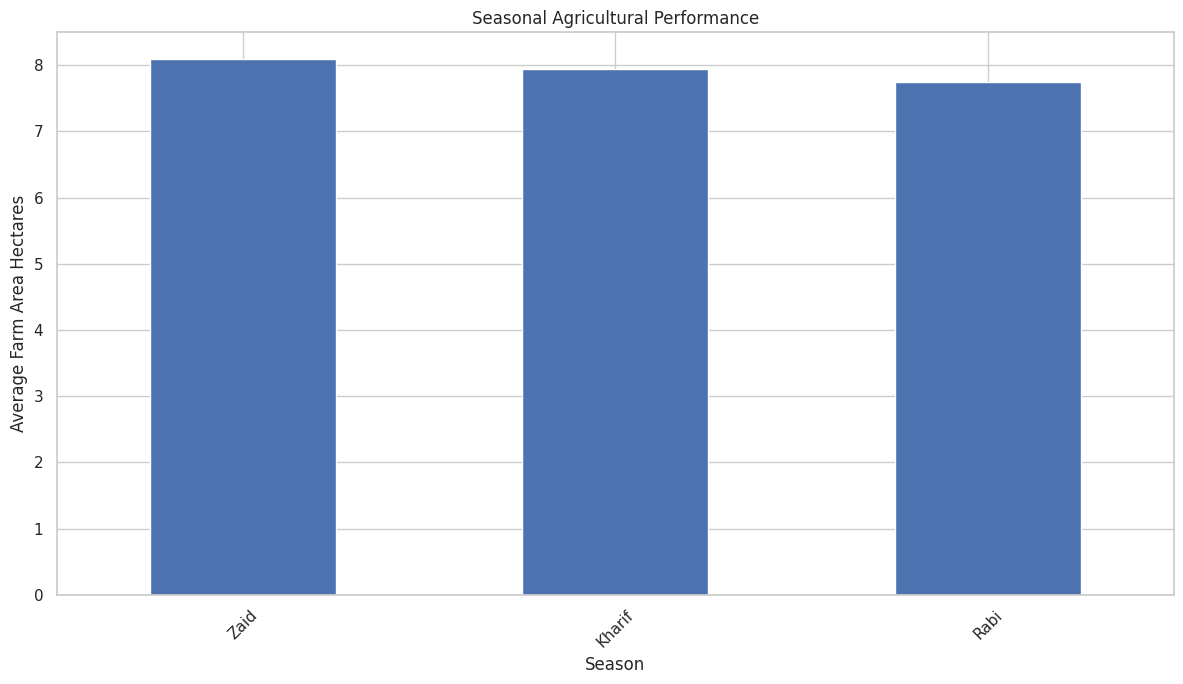

In [ ]:
plt.figure(figsize=(12,7))

season_means.sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Seasonal Agricultural Performance")
plt.xlabel("Season")
plt.ylabel(f"Average {performance_col.replace('_', ' ').title()}")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
output_file = "cleaned_agriculture_dataset.csv"

df.to_csv(
    output_file,
    index=False
)

print("Cleaned dataset saved as:", output_file)

Cleaned dataset saved as: cleaned_agriculture_dataset.csv


In [ ]:
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Conclusion**

The Seasonal Agriculture Performance Analysis demonstrates that agricultural performance can vary across seasons due to differences in environmental conditions, farming practices, resource usage, and economic factors. The analysis helps identify the best and lowest-performing seasons, seasonal trends, variations in resource consumption, and relationships between environmental factors and agricultural outcomes.

Regional and seasonal comparisons provide a clearer understanding of how agricultural performance changes across different areas. Statistical analysis and visualizations further help determine whether observed seasonal differences are meaningful and identify unusual patterns.

Overall, the findings can support better seasonal agricultural planning by helping stakeholders allocate resources effectively, understand low-performing periods, and make data-driven decisions for improving agricultural productivity. This aligns with the project objective of identifying seasonal patterns, relationships, significant observations, and evidence-based recommendations.